In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/MukeshKorri/World-Happiness-Data-science-Report/main/World-happiness-report-updated_2024.csv"

df = pd.read_csv(url, encoding='latin-1')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (2363, 11)


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (2363, 11)

Column Names:
['Country name', 'year', 'Life Ladder', 'Log GDP per capita', 'Social support', 'Healthy life expectancy at birth', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Positive affect', 'Negative affect']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   object 
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                   

,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
count,2363.000000,2363.000000,2335.000000,2350.000000,2300.000000,2327.000000,2282.000000,2238.000000,2339.000000,2347.000000
mean,2014.763860,5.483566,9.399671,0.809369,63.401828,0.750282,0.000098,0.743971,0.651882,0.273151
std,5.059436,1.125522,1.152069,0.121212,6.842644,0.139357,0.161388,0.184865,0.106240,0.087131
min,2005.000000,1.281000,5.527000,0.228000,6.720000,0.228000,-0.340000,0.035000,0.179000,0.083000
25%,2011.000000,4.647000,8.506500,0.744000,59.195000,0.661000,-0.112000,0.687000,0.572000,0.209000
50%,2015.000000,5.449000,9.503000,0.834500,65.100000,0.771000,-0.022000,0.798500,0.663000,0.262000
75%,2019.000000,6.323500,10.392500,0.904000,68.552500,0.862000,0.093750,0.867750,0.737000,0.326000
max,2023.000000,8.019000,11.676000,0.987000,74.600000,0.985000,0.700000,0.983000,0.884000,0.705000



First 5 Records:


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   28
Social support                       13
Healthy life expectancy at birth     63
Freedom to make life choices         36
Generosity                           81
Perceptions of corruption           125
Positive affect                      24
Negative affect                      16
dtype: int64

Total Missing Values:
386

Duplicate Records:
0


In [7]:
df = df.drop_duplicates().copy()

numeric_columns = df.select_dtypes(
    include=np.number
).columns

df[numeric_columns] = df[numeric_columns].replace(
    [np.inf, -np.inf], np.nan
)

print("Dataset cleaned successfully!")

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

Dataset cleaned successfully!

Remaining Missing Values:
Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   28
Social support                       13
Healthy life expectancy at birth     63
Freedom to make life choices         36
Generosity                           81
Perceptions of corruption           125
Positive affect                      24
Negative affect                      16
dtype: int64

Cleaned Dataset Shape: (2363, 11)


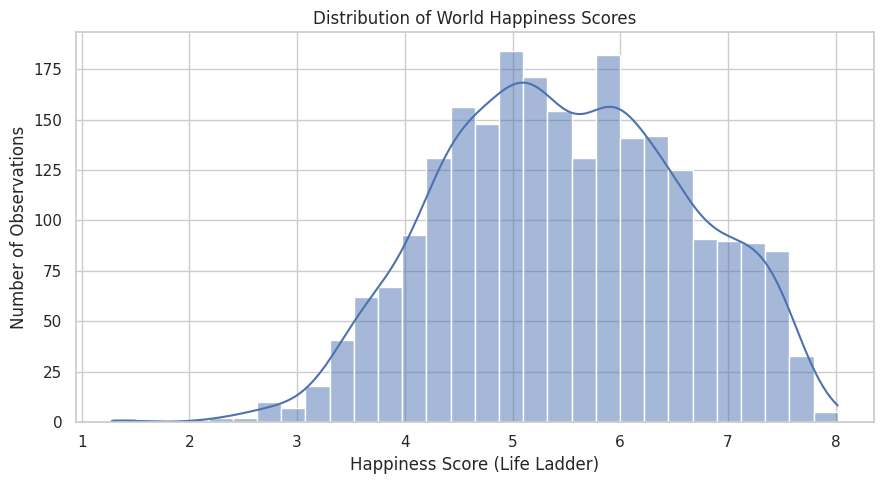

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df['Life Ladder'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of World Happiness Scores')
plt.xlabel('Happiness Score (Life Ladder)')
plt.ylabel('Number of Observations')

plt.tight_layout()
plt.savefig('happiness_distribution.png')
plt.show()

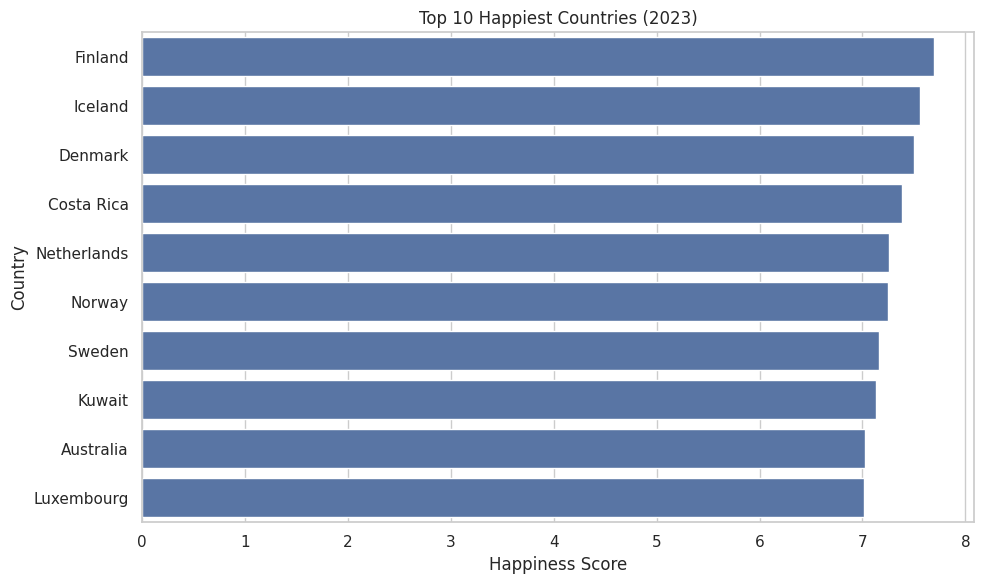

,Country name,Life Ladder
680,Finland,7.699
886,Iceland,7.562
556,Denmark,7.504
490,Costa Rica,7.384
1498,Netherlands,7.255
1594,Norway,7.249
2004,Sweden,7.161
1129,Kuwait,7.130
97,Australia,7.025
1249,Luxembourg,7.016


In [9]:
latest_year = df.loc[
    df['Life Ladder'].notna(), 'year'
].max()

latest_data = df[df['year'] == latest_year].copy()

top_countries = latest_data.nlargest(
    10, 'Life Ladder'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_countries,
    x='Life Ladder',
    y='Country name'
)

plt.title(f'Top 10 Happiest Countries ({latest_year})')
plt.xlabel('Happiness Score')
plt.ylabel('Country')

plt.tight_layout()
plt.savefig('top_10_happiest_countries.png')
plt.show()

display(top_countries[['Country name', 'Life Ladder']])

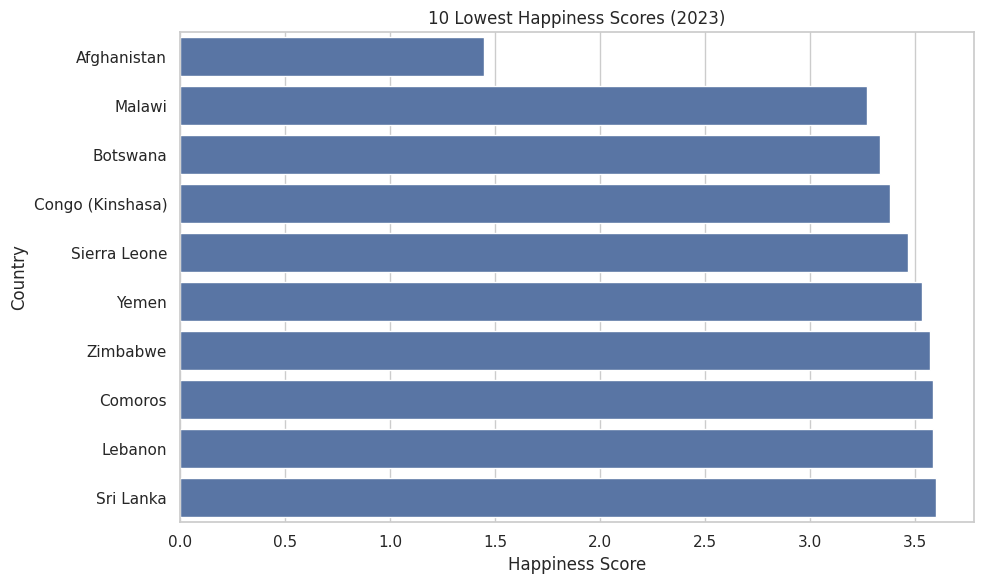

In [10]:
bottom_countries = latest_data.nsmallest(
    10, 'Life Ladder'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=bottom_countries,
    x='Life Ladder',
    y='Country name'
)

plt.title(f'10 Lowest Happiness Scores ({latest_year})')
plt.xlabel('Happiness Score')
plt.ylabel('Country')

plt.tight_layout()
plt.savefig('lowest_10_happiness_countries.png')
plt.show()

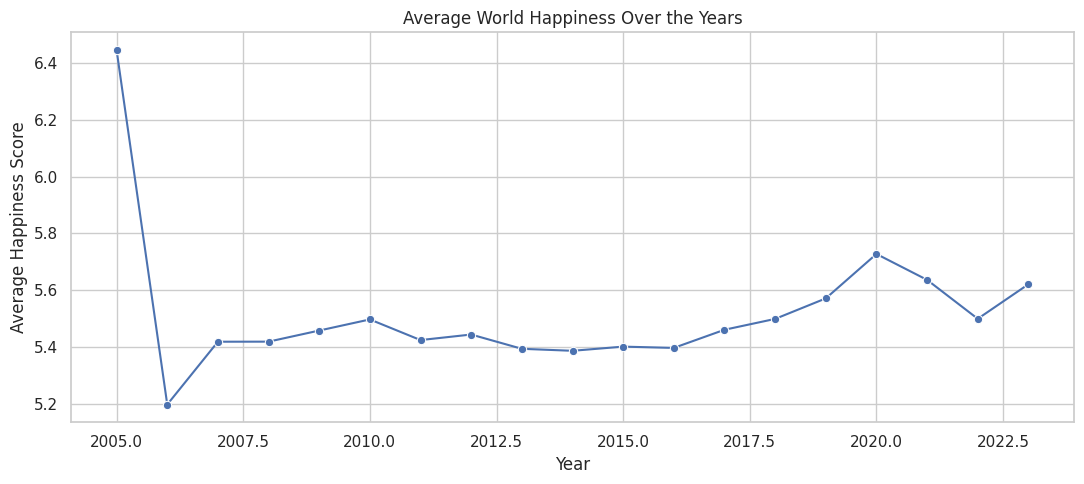

,year,Life Ladder
9,2014,5.386264
10,2015,5.400944
11,2016,5.396447
12,2017,5.460408
13,2018,5.498674
14,2019,5.570965
15,2020,5.727517
16,2021,5.636246
17,2022,5.499100
18,2023,5.620848


In [11]:
yearly_happiness = df.groupby('year')[
    'Life Ladder'
].mean().reset_index()

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=yearly_happiness,
    x='year',
    y='Life Ladder',
    marker='o'
)

plt.title('Average World Happiness Over the Years')
plt.xlabel('Year')
plt.ylabel('Average Happiness Score')

plt.tight_layout()
plt.savefig('happiness_yearly_trend.png')
plt.show()

display(yearly_happiness.tail(10))

In [12]:
if 'Regional indicator' in df.columns:

    regional_happiness = latest_data.groupby(
        'Regional indicator'
    )['Life Ladder'].mean().sort_values(
        ascending=False
    ).reset_index()

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=regional_happiness,
        x='Life Ladder',
        y='Regional indicator'
    )

    plt.title(f'Average Happiness by Region ({latest_year})')
    plt.xlabel('Average Happiness Score')
    plt.ylabel('Region')

    plt.tight_layout()
    plt.savefig('regional_happiness.png')
    plt.show()

    display(regional_happiness)

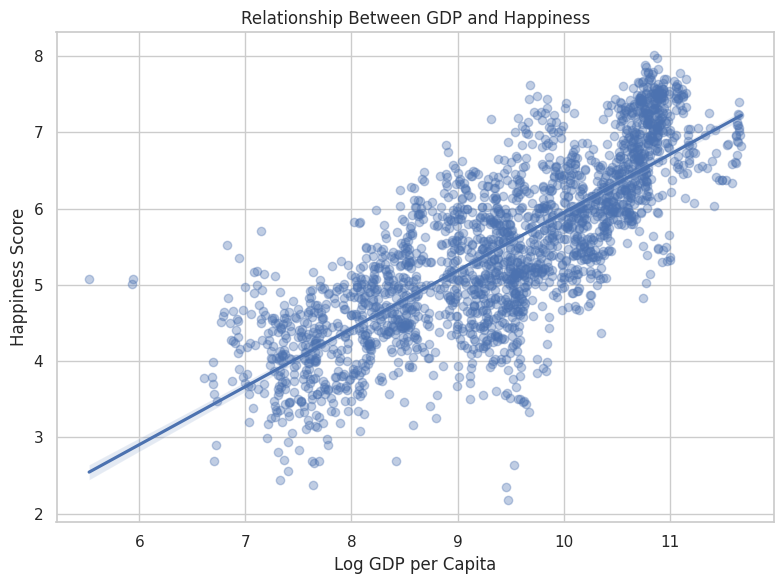

In [13]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='Log GDP per capita',
    y='Life Ladder',
    scatter_kws={'alpha': 0.35}
)

plt.title('Relationship Between GDP and Happiness')
plt.xlabel('Log GDP per Capita')
plt.ylabel('Happiness Score')

plt.tight_layout()
plt.savefig('gdp_vs_happiness.png')
plt.show()

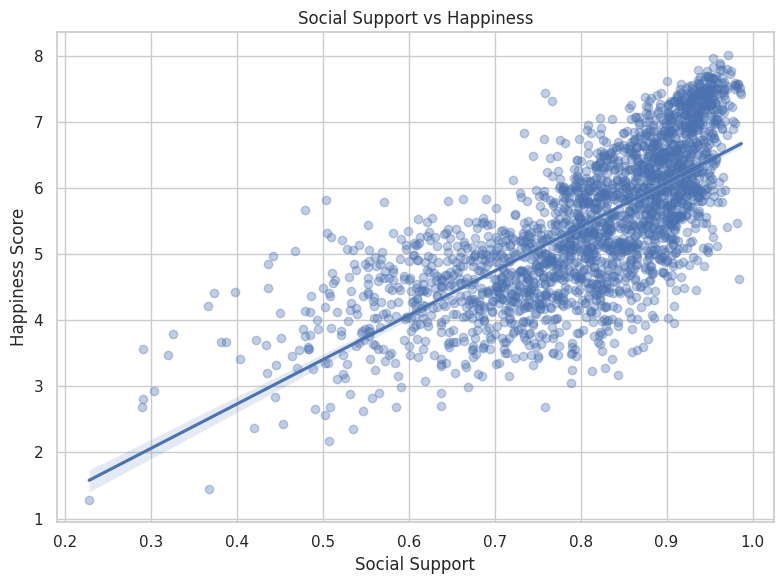

In [14]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='Social support',
    y='Life Ladder',
    scatter_kws={'alpha': 0.35}
)

plt.title('Social Support vs Happiness')
plt.xlabel('Social Support')
plt.ylabel('Happiness Score')

plt.tight_layout()
plt.savefig('social_support_vs_happiness.png')
plt.show()

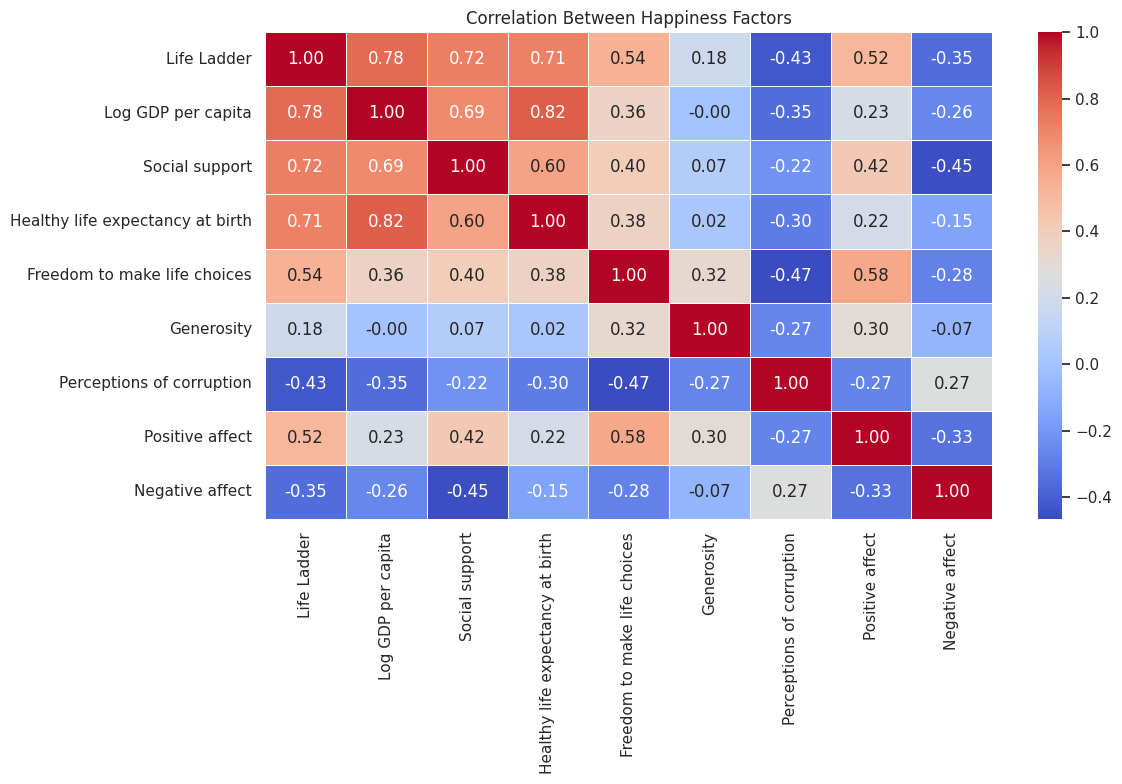

In [15]:
correlation_columns = [
    'Life Ladder',
    'Log GDP per capita',
    'Social support',
    'Healthy life expectancy at birth',
    'Freedom to make life choices',
    'Generosity',
    'Perceptions of corruption',
    'Positive affect',
    'Negative affect'
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Happiness Factors')

plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

In [16]:
happiness_correlations = correlation_matrix[
    'Life Ladder'
].sort_values(ascending=False)

print("Factors correlated with happiness:")
display(happiness_correlations)

Factors correlated with happiness:


,Life Ladder
Life Ladder,1.000000
Log GDP per capita,0.783556
Social support,0.722738
Healthy life expectancy at birth,0.714927
Freedom to make life choices,0.538210
Positive affect,0.515283
Generosity,0.177398
Negative affect,-0.352412
Perceptions of corruption,-0.430485


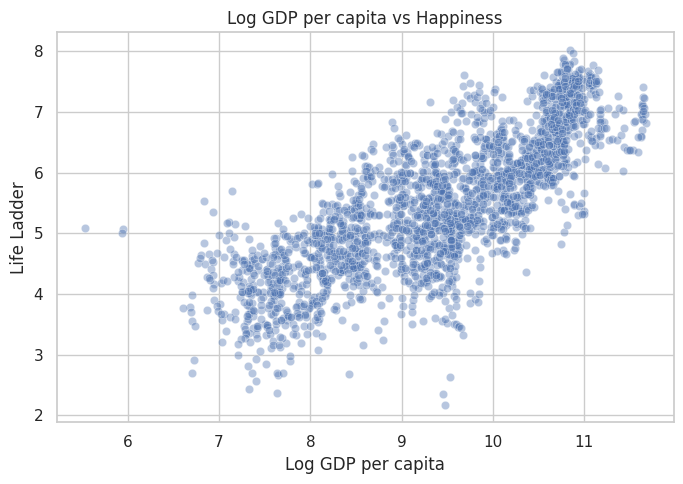

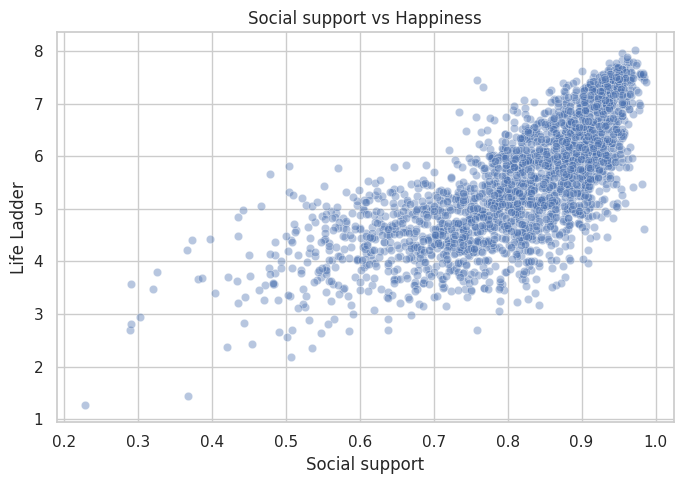

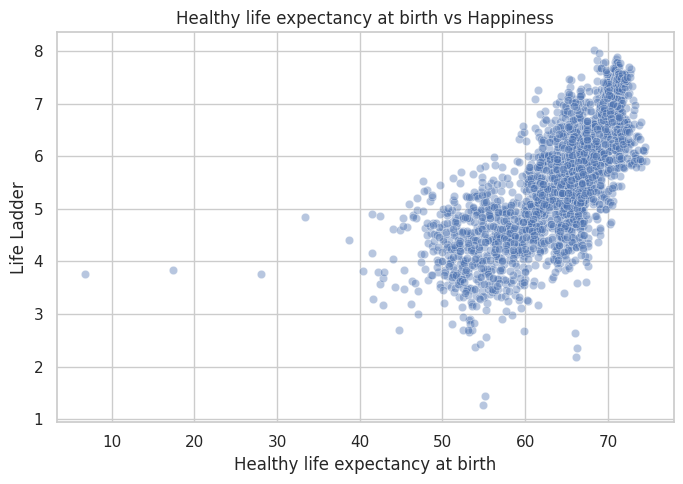

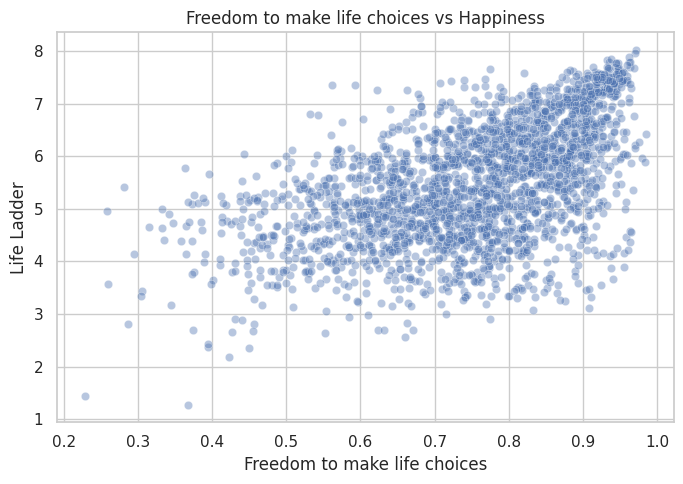

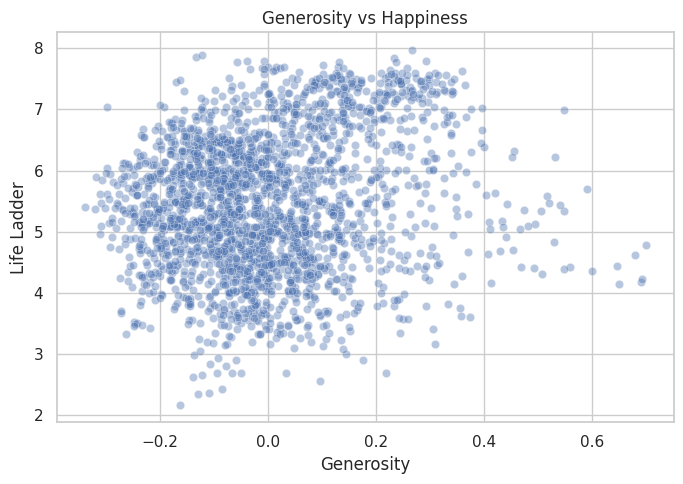

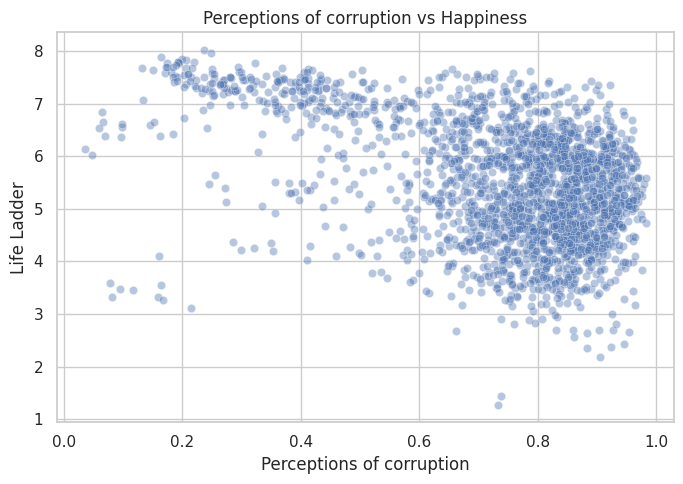

In [17]:
factors = [
    'Log GDP per capita',
    'Social support',
    'Healthy life expectancy at birth',
    'Freedom to make life choices',
    'Generosity',
    'Perceptions of corruption'
]

for factor in factors:

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=factor,
        y='Life Ladder',
        alpha=0.4
    )

    plt.title(f'{factor} vs Happiness')
    plt.tight_layout()

    filename = factor.lower().replace(' ', '_') + '.png'
    plt.savefig(filename)
    plt.show()

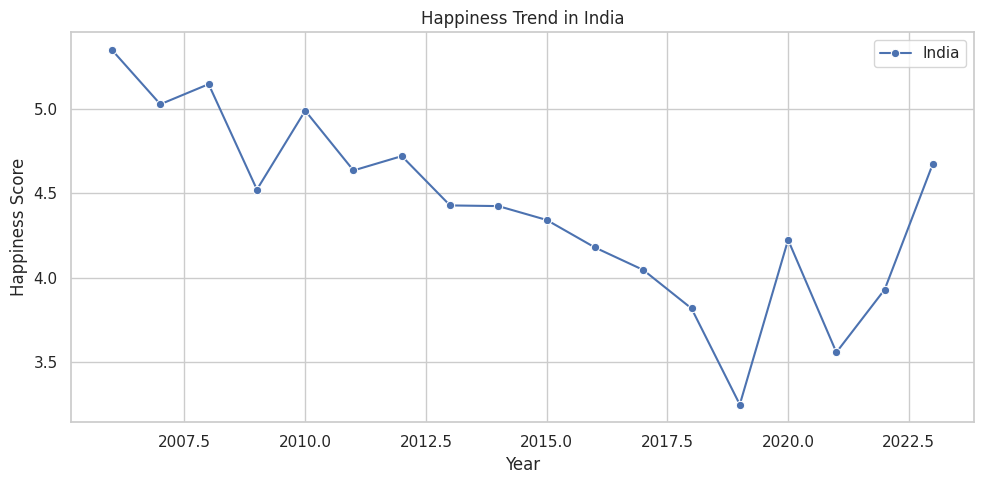

,year,Life Ladder
887,2006,5.348
888,2007,5.027
889,2008,5.146
890,2009,4.522
891,2010,4.989
892,2011,4.635
893,2012,4.720
894,2013,4.428
895,2014,4.424
896,2015,4.342


In [18]:
india_data = df[
    df['Country name'] == 'India'
].sort_values('year')

if not india_data.empty:

    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=india_data,
        x='year',
        y='Life Ladder',
        marker='o',
        label='India'
    )

    plt.title('Happiness Trend in India')
    plt.xlabel('Year')
    plt.ylabel('Happiness Score')

    plt.tight_layout()
    plt.savefig('india_happiness_trend.png')
    plt.show()

    display(
        india_data[['year', 'Life Ladder']]
    )
else:
    print("India data is not available.")

In [19]:
print("WORLD HAPPINESS EDA SUMMARY")

print("\nTotal Countries:")
print(df['Country name'].nunique())

print("\nYears Covered:")
print(df['year'].min(), "to", df['year'].max())

print("\nAverage Happiness Score:")
print(round(df['Life Ladder'].mean(), 2))

print("\nHighest Happiness Score:")
print(round(df['Life Ladder'].max(), 2))

print("\nLowest Happiness Score:")
print(round(df['Life Ladder'].min(), 2))

print("\nTop Correlated Factors:")
display(happiness_correlations.iloc[1:5])

WORLD HAPPINESS EDA SUMMARY

Total Countries:
165

Years Covered:
2005 to 2023

Average Happiness Score:
5.48

Highest Happiness Score:
8.02

Lowest Happiness Score:
1.28

Top Correlated Factors:


,Life Ladder
Log GDP per capita,0.783556
Social support,0.722738
Healthy life expectancy at birth,0.714927
Freedom to make life choices,0.538210


In [20]:
df.to_csv(
    'cleaned_world_happiness_dataset.csv',
    index=False
)

yearly_happiness.to_csv(
    'yearly_happiness_summary.csv',
    index=False
)

happiness_correlations.to_csv(
    'happiness_correlation_results.csv'
)

print("All files saved successfully!")

All files saved successfully!


In [21]:
from google.colab import files

output_files = [
    'cleaned_world_happiness_dataset.csv',
    'yearly_happiness_summary.csv',
    'happiness_correlation_results.csv',
    'happiness_distribution.png',
    'top_10_happiest_countries.png',
    'lowest_10_happiness_countries.png',
    'happiness_yearly_trend.png',
    'regional_happiness.png',
    'gdp_vs_happiness.png',
    'social_support_vs_happiness.png',
    'correlation_heatmap.png',
    'india_happiness_trend.png'
]

for filename in output_files:
    try:
        files.download(filename)
    except Exception:
        print("Optional file not generated:", filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (13 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>